# Music Genre Tagging — Part 2: Modelling & Client Reliability Report

**Client question (recap):** can genre tagging be automated, *how accurate will it be on new songs*, and *does it work for every genre*?

**How I answer it**
1. Hold back 20% of songs as an untouched **test set**. Every number quoted to the client comes from songs the model never saw.
2. Compare a range of models on the remaining 80% with **5-fold stratified cross-validation**, scored by **macro-F1** (every genre counts equally) and per-genre recall.
3. Test two ways of handling class imbalance (**class weights** and **SMOTE oversampling**), with SMOTE applied *inside* each training fold so no synthetic data leaks into evaluation.
4. Tune the best model, evaluate it once on the test set, and translate the results into an operating recommendation.

**Headline answer for the client:** the final model tags genres with a **macro-F1 of 0.86 and 87% accuracy on unseen songs**, and every genre is tagged correctly at least 78% of the time. Auto-tagging only confident predictions handles **83% of songs at 93% accuracy**, with the remainder going to human review.

## 1. Setup

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import loguniform, randint

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score,
                             classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from music_data import load_music, AUDIO, SOCIAL, TEMPORAL, FEATURES

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42

ROOT = Path("..")
IMAGES = ROOT / "images"; IMAGES.mkdir(exist_ok=True)
PROCESSED = ROOT / "data" / "processed"; PROCESSED.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GREY, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e8e7e3", "axes.axisbelow": True,
})

## 2. Load data and hold out a test set

In [2]:
music = load_music()
X = music[FEATURES]
y = music["genre"]
GENRES = y.value_counts().index.tolist()   # largest -> smallest

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Training songs: {len(X_train):,}   Test songs (held out): {len(X_test):,}")
pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).loc[GENRES]

Training songs: 6,488   Test songs (held out): 1,623


,train,test
genre,,
Rock,3113,779
Electronic,1736,434
Hip-Hop,728,182
Folk,699,175
Classical,212,53


The split is **stratified**, so every genre keeps the same share in both sets. Classical has only 53 test songs, so its test-set scores will be the least precise. I come back to this when reporting uncertainty.

## 3. Model comparison (5-fold cross-validation on the training set)

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_evaluate(name, model):
    """Fit on 4 folds, predict the 5th; return fold scores and pooled out-of-fold predictions."""
    start = time.time()
    oof = pd.Series(index=y_train.index, dtype=object)
    fold_f1 = []
    for tr, va in cv.split(X_train, y_train):
        m = model.fit(X_train.iloc[tr], y_train.iloc[tr])
        pred = m.predict(X_train.iloc[va])
        oof.iloc[va] = pred
        fold_f1.append(f1_score(y_train.iloc[va], pred, average="macro"))
    recalls = recall_score(y_train, oof, labels=GENRES, average=None)
    row = {"model": name,
           "macro_f1": np.mean(fold_f1), "macro_f1_sd": np.std(fold_f1),
           "accuracy": accuracy_score(y_train, oof),
           **{f"recall_{g}": r for g, r in zip(GENRES, recalls)},
           "minutes": (time.time() - start) / 60}
    print(f"{name:<38} macro-F1 {row['macro_f1']:.3f} ± {row['macro_f1_sd']:.3f}   "
          f"accuracy {row['accuracy']:.3f}   ({row['minutes']:.1f} min)")
    return row

candidates = {
    "Baseline: always predict Rock": DummyClassifier(strategy="most_frequent"),
    "Logistic regression (balanced)": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "SVM, RBF kernel (balanced)": Pipeline([
        ("scale", StandardScaler()),
        ("clf", SVC(class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random forest (balanced)": RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting (no weighting)": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Gradient boosting + class weights": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient boosting + SMOTE": ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

results = [cv_evaluate(name, model) for name, model in candidates.items()]

Baseline: always predict Rock          macro-F1 0.130 ± 0.000   accuracy 0.480   (0.0 min)


Logistic regression (balanced)         macro-F1 0.768 ± 0.008   accuracy 0.784   (0.3 min)


SVM, RBF kernel (balanced)             macro-F1 0.777 ± 0.012   accuracy 0.795   (0.3 min)


Random forest (balanced)               macro-F1 0.746 ± 0.016   accuracy 0.779   (0.7 min)


Gradient boosting (no weighting)       macro-F1 0.832 ± 0.006   accuracy 0.850   (0.8 min)


Gradient boosting + class weights      macro-F1 0.836 ± 0.009   accuracy 0.850   (3.3 min)


Gradient boosting + SMOTE              macro-F1 0.824 ± 0.011   accuracy 0.840   (1.1 min)


**What the comparison shows**

- **The dummy baseline proves why accuracy misleads.** Always guessing "Rock" scores **48% accuracy** but a macro-F1 of only **0.13**, because it gets every other genre wrong.
- **Simple models are respectable.** Balanced logistic regression reaches 0.77 and a balanced RBF SVM 0.78. Logistic regression actually has the best Hip-Hop, Folk and Classical recall of any model, but it loses too much on Rock and Electronic.
- **Random forest neglects small genres.** It has the highest Rock recall of any real model (94%) but tags only **44% of Folk** songs correctly, even with balanced class weights.
- **Gradient boosting is clearly strongest** (0.82–0.84), because it captures non-linear patterns across the 237 features.
- **Handling the imbalance:** class weights gave a small lift over no weighting (0.836 vs 0.832), mainly by improving Folk (72% vs 69%) and Hip-Hop (77% vs 72%) recall. **SMOTE did slightly worse (0.824)** even when applied correctly inside each training fold. Synthetic songs built by interpolating between real ones add noise rather than useful signal here.

## 4. Does hyperparameter tuning help?

In [4]:
search = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", max_iter=600, early_stopping=True,
                                   validation_fraction=0.1, n_iter_no_change=25,
                                   random_state=RANDOM_STATE),
    param_distributions={
        "learning_rate": loguniform(0.03, 0.3),
        "max_leaf_nodes": randint(15, 64),
        "min_samples_leaf": randint(10, 60),
        "l2_regularization": loguniform(1e-3, 1.0),
    },
    n_iter=12, scoring="f1_macro",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1)
start = time.time()
search.fit(X_train, y_train)
print(f"Search took {(time.time() - start) / 60:.1f} min")
best_params = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
print("Best parameters:", best_params)

tuned = HistGradientBoostingClassifier(class_weight="balanced", max_iter=600, early_stopping=True,
                                       validation_fraction=0.1, n_iter_no_change=25,
                                       random_state=RANDOM_STATE, **search.best_params_)
candidates["Gradient boosting, tuned"] = tuned
results.append(cv_evaluate("Gradient boosting, tuned", tuned))

Search took 22.4 min
Best parameters: {'l2_regularization': np.float64(0.0349), 'learning_rate': np.float64(0.1174), 'max_leaf_nodes': 17, 'min_samples_leaf': 46}


Gradient boosting, tuned               macro-F1 0.829 ± 0.007   accuracy 0.843   (3.0 min)


In [5]:
comparison = pd.DataFrame(results).set_index("model")
# The final model is chosen on cross-validation alone, before the test set is touched
FINAL_NAME = comparison["macro_f1"].idxmax()
print("Selected final model:", FINAL_NAME)
show = comparison[["macro_f1", "macro_f1_sd", "accuracy"] + [f"recall_{g}" for g in GENRES]]
show.round(3).sort_values("macro_f1", ascending=False)

Selected final model: Gradient boosting + class weights


,macro_f1,macro_f1_sd,accuracy,recall_Rock,recall_Electronic,recall_Hip-Hop,recall_Folk,recall_Classical
model,,,,,,,,
Gradient boosting + class weights,0.836,0.009,0.850,0.907,0.831,0.772,0.724,0.868
Gradient boosting (no weighting),0.832,0.006,0.850,0.925,0.835,0.723,0.690,0.854
"Gradient boosting, tuned",0.829,0.007,0.843,0.888,0.825,0.777,0.745,0.882
Gradient boosting + SMOTE,0.824,0.011,0.840,0.883,0.829,0.766,0.737,0.882
"SVM, RBF kernel (balanced)",0.777,0.012,0.795,0.786,0.829,0.787,0.753,0.811
Logistic regression (balanced),0.768,0.008,0.784,0.785,0.764,0.820,0.757,0.906
Random forest (balanced),0.746,0.016,0.779,0.935,0.695,0.628,0.435,0.835
Baseline: always predict Rock,0.130,0.000,0.480,1.000,0.000,0.000,0.000,0.000


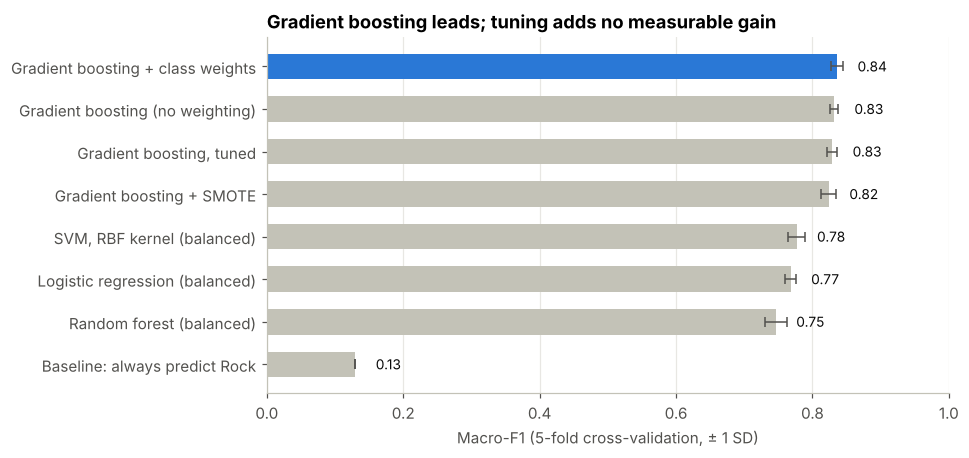

In [6]:
order = comparison.sort_values("macro_f1")
colors = [BLUE if m == FINAL_NAME else GREY for m in order.index]

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(order.index, order["macro_f1"], xerr=order["macro_f1_sd"], color=colors, height=0.6,
               error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 3})
for b, v in zip(bars, order["macro_f1"]):
    ax.text(v + 0.03, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Macro-F1 (5-fold cross-validation, ± 1 SD)")
ax.grid(axis="y", visible=False)
ax.set_title("Gradient boosting leads; tuning adds no measurable gain")
fig.savefig(IMAGES / "model_comparison.png")
plt.show()

## 5. Final check on the held-out test set

The model with the best cross-validated macro-F1 is now trained on all training songs and evaluated **once** on the 1,623 test songs it has never seen.

In [7]:
final = candidates[FINAL_NAME].fit(X_train, y_train)
print("Final model:", FINAL_NAME)
y_pred = final.predict(X_test)
proba = final.predict_proba(X_test)
classes = list(final.classes_)

test_macro_f1 = f1_score(y_test, y_pred, average="macro")
test_acc = accuracy_score(y_test, y_pred)

# 95% bootstrap intervals for the headline numbers
rng = np.random.default_rng(RANDOM_STATE)
yt, yp = y_test.to_numpy(), np.asarray(y_pred)
boot_f1, boot_acc = [], []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    boot_f1.append(f1_score(yt[idx], yp[idx], average="macro"))
    boot_acc.append(accuracy_score(yt[idx], yp[idx]))
f1_lo, f1_hi = np.percentile(boot_f1, [2.5, 97.5])
acc_lo, acc_hi = np.percentile(boot_acc, [2.5, 97.5])

print(f"Test macro-F1 : {test_macro_f1:.3f}  (95% CI {f1_lo:.3f}–{f1_hi:.3f})")
print(f"Test accuracy : {test_acc:.3f}  (95% CI {acc_lo:.3f}–{acc_hi:.3f})")
print()
print(classification_report(y_test, y_pred, labels=GENRES, digits=3))

Final model: Gradient boosting + class weights


Test macro-F1 : 0.863  (95% CI 0.843–0.881)
Test accuracy : 0.869  (95% CI 0.852–0.884)

              precision    recall  f1-score   support

        Rock      0.887     0.905     0.896       779
  Electronic      0.826     0.864     0.845       434
     Hip-Hop      0.902     0.813     0.855       182
        Folk      0.835     0.783     0.808       175
   Classical      0.978     0.849     0.909        53

    accuracy                          0.869      1623
   macro avg      0.886     0.843     0.863      1623
weighted avg      0.870     0.869     0.869      1623



In [8]:
genre_metrics = pd.DataFrame({
    "genre": GENRES,
    "test_songs": [int((y_test == g).sum()) for g in GENRES],
    "precision": precision_score(y_test, y_pred, labels=GENRES, average=None),
    "recall": recall_score(y_test, y_pred, labels=GENRES, average=None),
    "f1": f1_score(y_test, y_pred, labels=GENRES, average=None),
})
genre_metrics.round(3)

,genre,test_songs,precision,recall,f1
0,Rock,779,0.887,0.905,0.896
1,Electronic,434,0.826,0.864,0.845
2,Hip-Hop,182,0.902,0.813,0.855
3,Folk,175,0.835,0.783,0.808
4,Classical,53,0.978,0.849,0.909


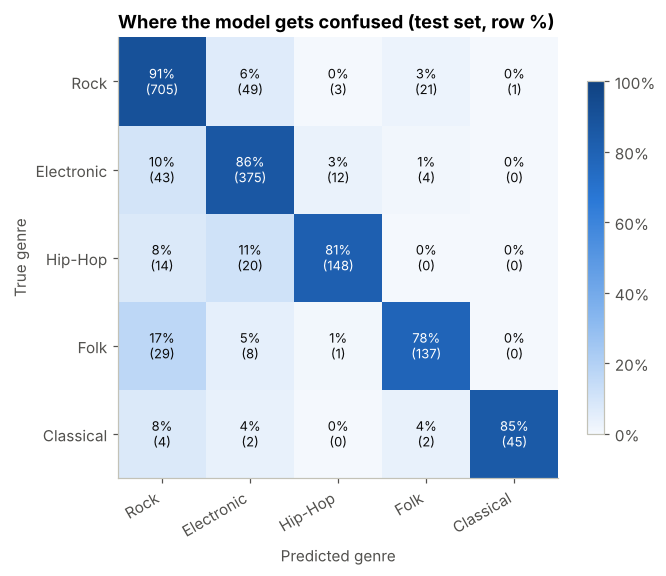

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=GENRES)
cm_pct = cm / cm.sum(axis=1, keepdims=True)
seq = LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#86b6ef", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(6.6, 5.2))
im = ax.imshow(cm_pct, cmap=seq, vmin=0, vmax=1)
ax.set_xticks(range(len(GENRES)), GENRES, rotation=30, ha="right")
ax.set_yticks(range(len(GENRES)), GENRES)
for i in range(len(GENRES)):
    for j in range(len(GENRES)):
        v = cm_pct[i, j]
        ax.text(j, i, f"{v:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.55 else INK)
ax.set_xlabel("Predicted genre"); ax.set_ylabel("True genre")
ax.grid(False)
ax.set_title("Where the model gets confused (test set, row %)")
fig.colorbar(im, ax=ax, shrink=0.8, format=mtick.PercentFormatter(1.0))
fig.savefig(IMAGES / "confusion_matrix.png")
plt.show()

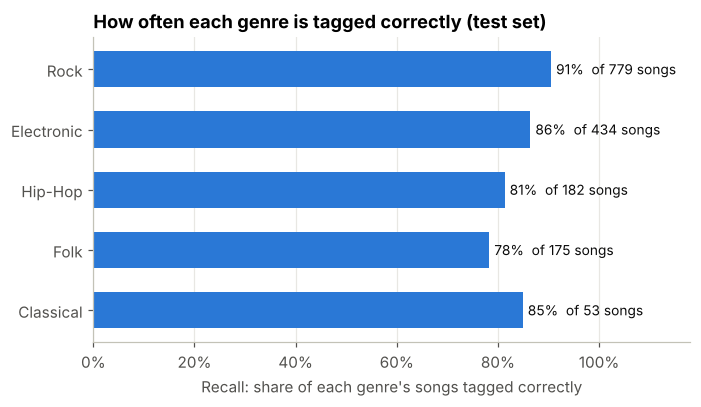

In [10]:
gm = genre_metrics.set_index("genre").loc[GENRES[::-1]]
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(gm.index, gm["recall"], color=BLUE, height=0.6)
for b, r, n in zip(bars, gm["recall"], gm["test_songs"]):
    ax.text(r + 0.01, b.get_y() + b.get_height() / 2, f"{r:.0%}  of {n} songs", va="center",
            fontsize=9, color=INK)
ax.set_xlim(0, 1.18)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Recall: share of each genre's songs tagged correctly")
ax.grid(axis="y", visible=False)
ax.set_title("How often each genre is tagged correctly (test set)")
fig.savefig(IMAGES / "genre_recall.png")
plt.show()

**Test-set results (1,623 unseen songs)**

- **Macro-F1 0.863** (95% bootstrap CI 0.843–0.881) and **accuracy 86.9%** (CI 85.2–88.4%).
- The cross-validated estimate was lower (0.836). Both sit within normal sampling variation, so I would tell the client to **expect a macro-F1 of roughly 0.84–0.86 on new songs**, using the more conservative CV figure as the planning number.
- **Every genre clears 78% recall:** Rock 91%, Electronic 86%, Classical 85%, Hip-Hop 81%, Folk 78%.
- **Classical predictions are the most trustworthy** (precision 98%: when the model says Classical, it is almost always right). Its recall estimate is the least precise, though, because the test set has only 53 Classical songs.

**Where the errors are.** Almost all mistakes involve **Rock or Electronic**, the two largest genres:
- **17% of Folk** songs are tagged as Rock, the single biggest weakness.
- **11% of Hip-Hop** is tagged as Electronic and 8% as Rock.
- Rock and Electronic are confused with each other in both directions (6% and 10%).
- Classical is almost never mistaken for anything else.

## 6. Which data matters most?

**Permutation importance:** shuffle one feature at a time on the test set and measure how much macro-F1 drops. A bigger drop means the model relies on that feature more.

In [11]:
start = time.time()
perm = permutation_importance(final, X_test, y_test, scoring="f1_macro", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1)
print(f"Permutation importance took {(time.time() - start) / 60:.1f} min")
importance = (pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean,
                            "sd": perm.importances_std})
              .assign(group=lambda d: np.select(
                  [d.feature.isin(AUDIO), d.feature.isin(SOCIAL)],
                  ["Audio descriptors (8)", "Artist popularity (5)"], "Temporal audio features (224)"))
              .sort_values("importance", ascending=False))
importance.head(15).round(4)

Permutation importance took 1.2 min


,feature,importance,sd,group
0,acousticness,0.0948,0.0058,Audio descriptors (8)
9,artist_familiarity,0.0392,0.0045,Artist popularity (5)
140,temporal_128,0.0278,0.0044,Temporal audio features (224)
8,artist_discovery,0.0275,0.0050,Artist popularity (5)
10,artist_hotttnesss,0.0193,0.0030,Artist popularity (5)
2,energy,0.0155,0.0014,Audio descriptors (8)
214,temporal_202,0.0090,0.0013,Temporal audio features (224)
1,danceability,0.0079,0.0024,Audio descriptors (8)
3,instrumentalness,0.0078,0.0023,Audio descriptors (8)
143,temporal_131,0.0061,0.0015,Temporal audio features (224)


group
Artist popularity (5)            17.9%
Audio descriptors (8)            26.5%
Temporal audio features (224)    55.6%
Name: importance, dtype: str


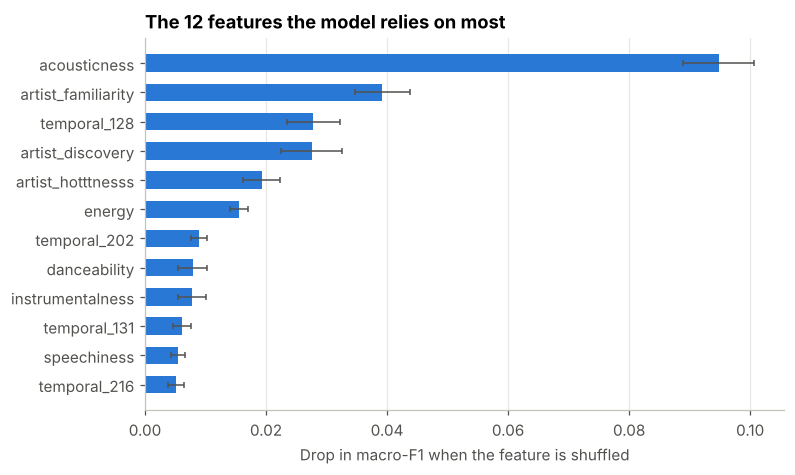

In [12]:
group_share = importance.groupby("group")["importance"].apply(lambda s: s.clip(lower=0).sum())
group_share = (group_share / group_share.sum()).sort_values()
print((group_share * 100).round(1).astype(str) + "%")

top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.barh(top["feature"], top["importance"], xerr=top["sd"], color=BLUE, height=0.6,
        error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
ax.set_xlabel("Drop in macro-F1 when the feature is shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("The 12 features the model relies on most")
fig.savefig(IMAGES / "feature_importance.png")
plt.show()

**What drives the predictions**

- **Acousticness is by far the most important single feature.** Shuffling it drops macro-F1 by about 0.09, more than double any other feature. It is what separates Classical and Folk from Electronic and Rock.
- **Artist popularity scores rank highly** (artist familiarity, discovery and "hotttnesss" are three of the top five). That is useful, but it is a caveat for the client: a brand-new artist with no popularity history will give the model less to go on.
- The 224 low-level temporal features together account for about 56% of the total importance, the 8 audio descriptors 27%, and the 5 popularity scores 18%. **The 13 named features carry 44% of the signal despite being only 5% of the columns.**

## 7. Turning the model into a workflow: auto-tag when confident

The model outputs a probability for each genre. If we only **auto-tag songs where the top probability is high** and send the rest to a human, we trade *coverage* (share of songs handled automatically) for *accuracy*.

In [13]:
confidence = proba.max(axis=1)
correct = (np.asarray(y_pred) == y_test.to_numpy())

rows = []
for t in np.round(np.arange(0.40, 0.96, 0.05), 2):
    keep = confidence >= t
    rows.append({"threshold": t, "coverage": keep.mean(),
                 "accuracy_auto_tagged": correct[keep].mean() if keep.any() else np.nan,
                 "songs_to_review": int((~keep).sum())})
tradeoff = pd.DataFrame(rows)
tradeoff.round(3)

,threshold,coverage,accuracy_auto_tagged,songs_to_review
0,0.40,0.997,0.870,5
1,0.45,0.992,0.873,13
2,0.50,0.978,0.880,35
3,0.55,0.957,0.887,69
4,0.60,0.933,0.898,108
5,0.65,0.909,0.908,148
6,0.70,0.886,0.917,185
7,0.75,0.862,0.923,224
8,0.80,0.829,0.932,278
9,0.85,0.792,0.940,338


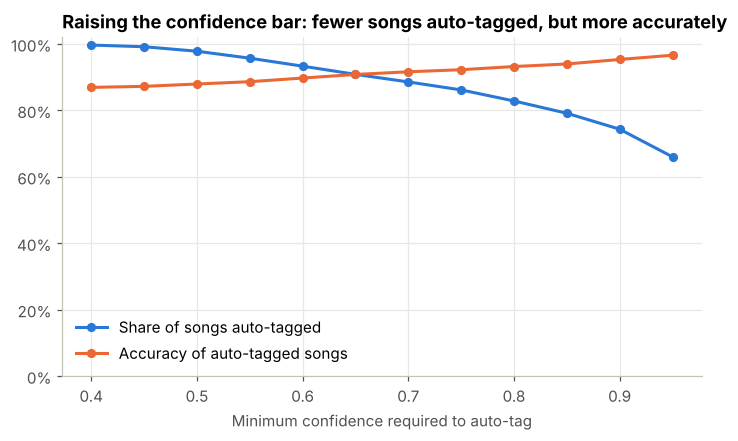

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(tradeoff.threshold, tradeoff.coverage, color=BLUE, lw=2, marker="o", ms=5,
        label="Share of songs auto-tagged")
ax.plot(tradeoff.threshold, tradeoff.accuracy_auto_tagged, color=ORANGE, lw=2, marker="o", ms=5,
        label="Accuracy of auto-tagged songs")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Minimum confidence required to auto-tag")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Raising the confidence bar: fewer songs auto-tagged, but more accurately")
fig.savefig(IMAGES / "confidence_tradeoff.png")
plt.show()

In [15]:
THRESHOLD = 0.80
keep = confidence >= THRESHOLD
by_genre = pd.DataFrame({"true_genre": y_test.to_numpy(), "auto": keep, "correct": correct})
policy = (by_genre.groupby("true_genre")
          .agg(songs=("auto", "size"), auto_tagged=("auto", "mean"),
               accuracy_when_auto=("correct", lambda s: s[by_genre.loc[s.index, "auto"]].mean()))
          .loc[GENRES])
print(f"At confidence >= {THRESHOLD:.0%}: {keep.mean():.1%} of songs auto-tagged, "
      f"{correct[keep].mean():.1%} of them correct; {(~keep).sum()} of {len(keep)} songs go to review.")
policy.round(3)

At confidence >= 80%: 82.9% of songs auto-tagged, 93.2% of them correct; 278 of 1623 songs go to review.


,songs,auto_tagged,accuracy_when_auto
true_genre,,,
Rock,779,0.882,0.951
Electronic,434,0.783,0.924
Hip-Hop,182,0.808,0.884
Folk,175,0.726,0.898
Classical,53,0.830,0.977


**A practical operating policy**

At a confidence threshold of **80%**:
- **83% of songs are auto-tagged**, and **93% of those tags are correct** (vs 87% if everything were auto-tagged).
- **278 of 1,623 songs (17%)** go to a human for review.
- The review queue is **weighted towards the hardest genres**: about 27% of Folk and 22% of Electronic songs go to review, against 12% of Rock.

The threshold is a business dial. Raising it to 90% gives 95% accuracy on 74% of songs; lowering it to 60% auto-tags 93% of songs at 90% accuracy. The right setting depends on how costly a wrong tag is compared with an editor's time.

## 8. Save outputs for the Power BI dashboard

In [16]:
comparison.reset_index().round(4).to_csv(PROCESSED / "model_comparison.csv", index=False)
genre_metrics.round(4).to_csv(PROCESSED / "test_genre_metrics.csv", index=False)
pd.DataFrame(cm, index=GENRES, columns=GENRES).rename_axis("true_genre").reset_index() \
    .melt(id_vars="true_genre", var_name="predicted_genre", value_name="songs") \
    .to_csv(PROCESSED / "confusion_matrix.csv", index=False)
pd.DataFrame({"song_id": y_test.index, "true_genre": y_test.to_numpy(), "predicted_genre": y_pred,
              "confidence": confidence.round(4), "correct": correct,
              "auto_tagged_at_80": keep}).to_csv(PROCESSED / "test_predictions.csv", index=False)
tradeoff.round(4).to_csv(PROCESSED / "confidence_tradeoff.csv", index=False)
importance.round(5).to_csv(PROCESSED / "feature_importance.csv", index=False)
music.groupby("genre")[[a for a in AUDIO if a != "tempo"]].mean().loc[GENRES].round(4) \
    .reset_index().to_csv(PROCESSED / "genre_profiles.csv", index=False)
print("Saved:", sorted(p.name for p in PROCESSED.glob("*.csv")))

Saved: ['confidence_tradeoff.csv', 'confusion_matrix.csv', 'feature_importance.csv', 'genre_profiles.csv', 'model_comparison.csv', 'test_genre_metrics.csv', 'test_predictions.csv']


## 9. Summary for the client

| Question | Answer |
|---|---|
| **Can genre tagging be automated?** | Yes. The model tags new songs with **~87% accuracy** and a **macro-F1 of 0.84–0.86**. |
| **Does it work for every genre?** | Yes, with caveats. Every genre is tagged correctly at least **78%** of the time. **Folk** is the weakest, most often mistaken for Rock. |
| **How should it be used?** | **Auto-tag when the model is ≥ 80% confident** (83% of songs, 93% accurate) and route the rest, about 1 in 6 songs, to an editor. |
| **What would improve it?** | More Folk and Classical training songs; features that separate acoustic Rock from Folk; and caution with brand-new artists that lack popularity data. |

**What I tried and rejected:** random forest (neglected small genres), SMOTE oversampling (slightly worse than class weights), and hyperparameter tuning (no gain over the defaults, so the simpler model was kept).